## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Dylan Wang

**Date:** 10/12/2026

In [2]:
# Q1.1:
# libs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from IPython.display import display

# the code from question 1
def createData(noise, N=50):
    np.random.seed(100)
    X1 = np.array([np.random.normal(1, noise, N),
                   np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N),
                   np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N),
                   np.random.normal(3, noise, N)])

    return pd.concat([
        pd.DataFrame({'x1': X1[0], 'x2': X1[1], 'group': 'a'}),
        pd.DataFrame({'x1': X2[0], 'x2': X2[1], 'group': 'b'}),
        pd.DataFrame({'x1': X3[0], 'x2': X3[1], 'group': 'c'})
    ])

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {
    0.125: df0_125, 0.25: df0_25, 0.5: df0_5,
    1.0: df1_0, 2.0: df2_0
}
ks = range(1, 11)

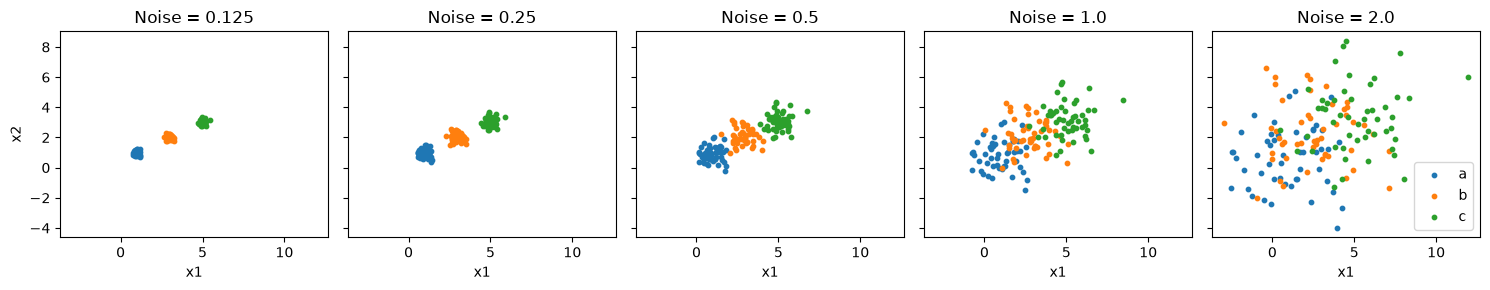

In [3]:
# Q1.2:
fig, axes = plt.subplots(1, 5, figsize=(15, 3), sharex=True, sharey=True)

for ax, (noise, df) in zip(axes, datasets.items()):
    for group, points in df.groupby('group'):
        ax.scatter(points['x1'], points['x2'], label=group, s=10)
    ax.set_title(f'Noise = {noise}')
    ax.set_xlabel('x1')

axes[0].set_ylabel('x2')
axes[-1].legend()
plt.tight_layout()
plt.show()

At noise 0.125 and 0.25, the three clusters are clearly separated.
As noise increases, the points spread out and overlap.
At noise 1 and 2, the groups become much harder to distinguish.

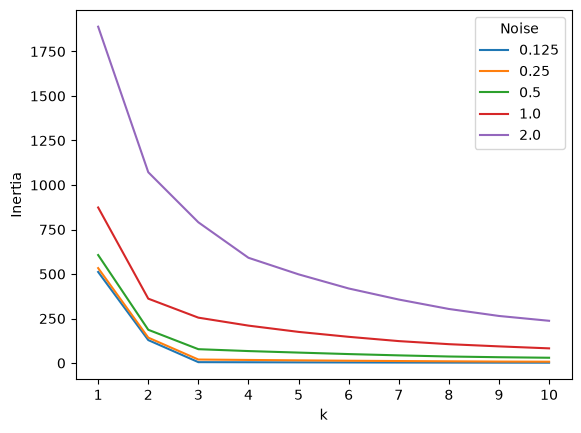

In [4]:
# Q1.3:
for noise, df in datasets.items():
    inertia = [
        KMeans(n_clusters=k, random_state=100, n_init=20)
        .fit(df[['x1', 'x2']]).inertia_
        for k in ks
    ]
    plt.plot(ks, inertia, label=str(noise))

plt.xlabel('k')
plt.ylabel('Inertia')
plt.xticks(ks)
plt.legend(title='Noise')
plt.show()

**Q1.3:** With low noise, the elbow is clear at k=3. Higher noise
increases inertia and makes the elbow less clear, so choosing k is harder.
All curves use the same vertical scale.

**Q1.4:** The elbow occurs when adding more clusters gives much smaller
improvements. Here, k=3 gives each low-noise group its own center.
Beyond that, extra clusters mostly split existing groups, so inertia
decreases only slightly.

In [6]:
# Q2.1:
df = pd.read_csv('data/SIPRI Military Expenditure Database.csv')
df = df[df['Year'] == 2020].dropna().copy()
df = df.drop(columns=['index'])
df['Country'] = df['Country'].str.strip()

features = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]

print('Countries:', len(df))
display(df[features].dtypes)
display(df.head())

Countries: 148


Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object

,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


Dropping missing values leaves 148 countries. The four spending variables
are already numeric. I removed the extra index column and stripped
whitespace from country names. Only the four spending variables are
used for clustering.

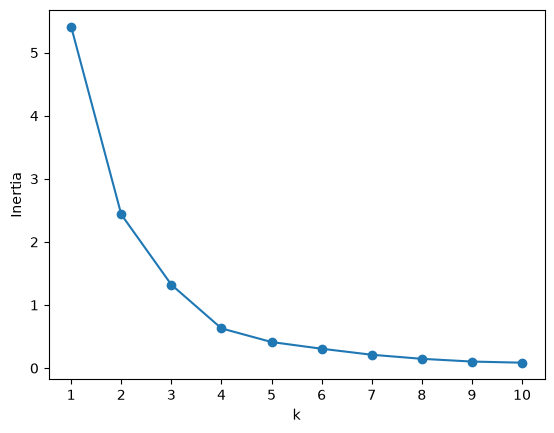

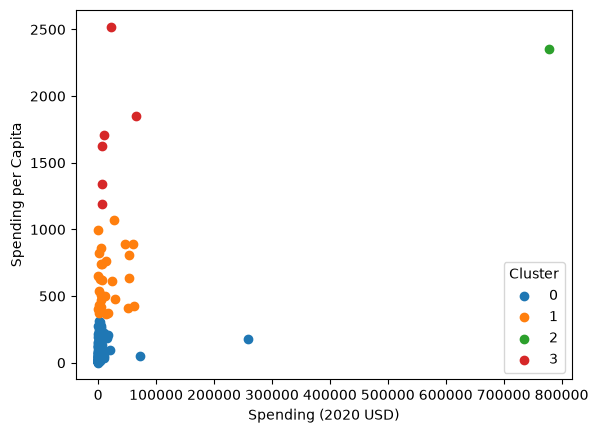

Spending (2020 USD)                                  \
                               count       mean       std        min   
spending_cluster                                                       
0                              111.0    4859.19  25405.74       8.62   
1                               30.0   17077.59  20583.05     405.79   
2                                1.0  778397.20       NaN  778397.20   
3                                6.0   19443.36  22861.51    6095.71   

                                                              \
                        25%        50%        75%        max   
spending_cluster                                               
0                    130.01     382.46    2297.03  257973.43   
1                   2294.04    5857.06   26296.00   61712.54   
2                 778397.20  778397.20  778397.20  778397.20   
3                   7023.25    8624.23   18857.07   64558.40   

                 Spending per Capita                                     \
                               count     mean     std      min      25%   
spending_cluster                                                          
0                              111.0    80.06   83.50     0.58    14.88   
1                               30.0   607.48  206.93   362.47   422.21   
2                                1.0  2351.63     NaN  2351.63  2351.63   
3                                6.0  1706.72  466.38  1193.60  1412.08   

                                             
                      50%      75%      max  
spending_cluster                             
0                   47.06   125.39   314.20  
1                  579.00   757.33  1070.62  
2                 2351.63  2351.63  2351.63  
3                 1665.45  1817.22  2520.40

,Country,spending_cluster,Spending (2020 USD),Spending per Capita
5540,United States of America,2,778397.2,2351.631858


In [7]:
# Q2.2 

# scree plot:
X = MinMaxScaler().fit_transform(df[features[:2]])

inertia = [
    KMeans(n_clusters=k, random_state=100, n_init=20).fit(X).inertia_
    for k in ks
]

plt.plot(ks, inertia, 'o-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.xticks(ks)
plt.show()

# clustering and results:
df['spending_cluster'] = KMeans(
    n_clusters=4, random_state=100, n_init=20
).fit_predict(X)

for cluster, group in df.groupby('spending_cluster'):
    plt.scatter(group[features[0]], group[features[1]], label=str(cluster))

plt.xlabel(features[0])
plt.ylabel(features[1])
plt.legend(title='Cluster')
plt.show()

display(df.groupby('spending_cluster')[features[:2]].describe().round(2))
display(df.loc[df['Country'] == 'United States of America',
               ['Country', 'spending_cluster'] + features[:2]])

I chose k=4 because the scree plot flattens noticeably after 4.
The clusters contain 111, 30, 1, and 6 countries. They mainly separate
low, moderate, and high per-capita spending, plus the US.

The US is alone in cluster 2 because its total spending is much higher.
The other high-per-capita group includes Israel, Kuwait, Norway, Oman,
Saudi Arabia, and Singapore.

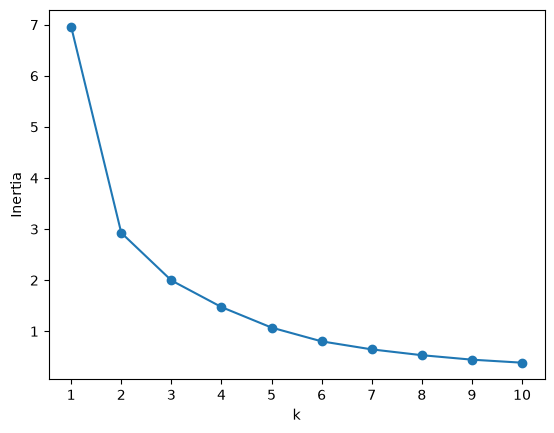

In [8]:
# Q2.3:

# scree plot:
X = MinMaxScaler().fit_transform(df[features[2:]])

inertia = [
    KMeans(n_clusters=k, random_state=100, n_init=20).fit(X).inertia_
    for k in ks
]

plt.plot(ks, inertia, 'o-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.xticks(ks)
plt.show()

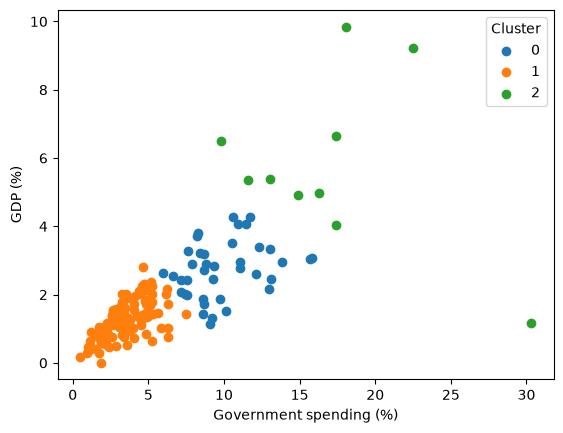

Percent of Government Spending                              \
                                        count   mean    std    min    25%   
burden_cluster                                                              
0                                        39.0  0.099  0.024  0.060  0.082   
1                                        99.0  0.036  0.015  0.005  0.026   
2                                        10.0  0.171  0.059  0.098  0.135   

                                    Percent of GDP                       \
                  50%    75%    max          count   mean    std    min   
burden_cluster                                                            
0               0.092  0.113  0.158           39.0  0.027  0.008  0.011   
1               0.034  0.047  0.075           99.0  0.013  0.006  0.000   
2               0.168  0.179  0.303           10.0  0.058  0.025  0.012   

                                            
                  25%    50%    75%    max  
burden_cluster                              
0               0.021  0.028  0.032  0.043  
1               0.008  0.013  0.017  0.028  
2               0.049  0.054  0.066  0.098

,Country,burden_cluster,Percent of Government Spending,Percent of GDP
5540,United States of America,0,0.081976,0.037179


In [9]:
# 2.3 clustering and results:
df['burden_cluster'] = KMeans(
    n_clusters=3, random_state=100, n_init=20
).fit_predict(X)

for cluster, group in df.groupby('burden_cluster'):
    plt.scatter(group[features[2]] * 100, group[features[3]] * 100,
                label=str(cluster))

plt.xlabel('Government spending (%)')
plt.ylabel('GDP (%)')
plt.legend(title='Cluster')
plt.show()

display(df.groupby('burden_cluster')[features[2:]].describe().round(3))
display(df.loc[df['Country'] == 'United States of America',
               ['Country', 'burden_cluster'] + features[2:]])

I chose k=3 for low, moderate, and high military spending burdens,
although the elbow is less clear and k=2 is also reasonable.
The clusters contain 39, 99, and 10 countries.

The US belongs to the moderate-burden group instead of standing alone.
Unlike part 2, these clusters reflect military spending relative to
government budgets and GDP. A high total spender does not necessarily
have the highest burden.

The percentage columns contain fractions, so the plot multiplies them
by 100. The describe table keeps the original values.

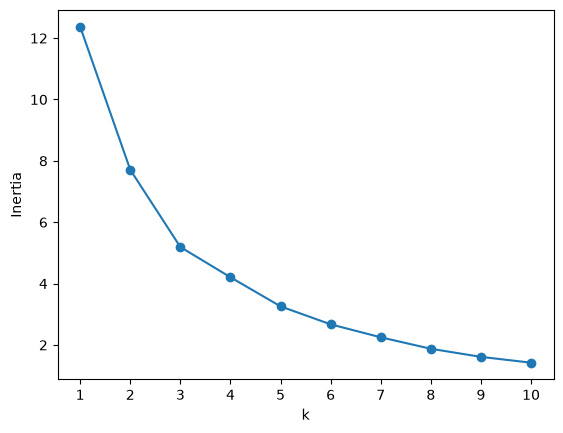

In [10]:
# Q2.4
# scree plot

X = MinMaxScaler().fit_transform(df[features])

inertia = [
    KMeans(n_clusters=k, random_state=100, n_init=20).fit(X).inertia_
    for k in ks
]

plt.plot(ks, inertia, 'o-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.xticks(ks)
plt.show()

,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
all_cluster,,,,
0,7086.473,196.927,0.040,0.013
1,147964.582,1875.151,0.135,0.063
2,8786.087,212.689,0.123,0.033


all_cluster
0    111
1      6
2     31
dtype: int64
Countries in the US cluster:
['Israel', 'Kuwait', 'Oman', 'Saudi Arabia', 'Singapore', 'United States of America']


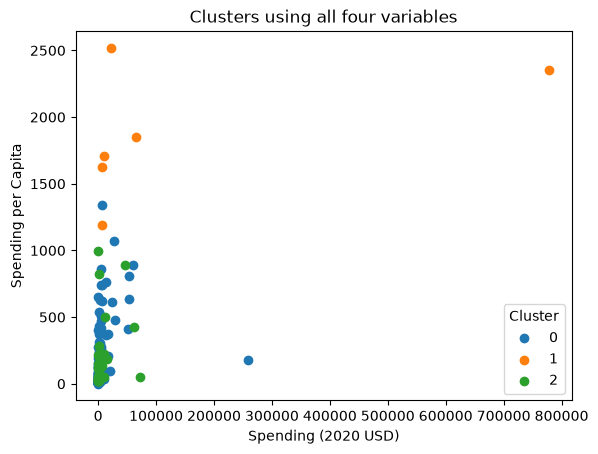

In [11]:
# 2.4 clustering and results:

df['all_cluster'] = KMeans(
    n_clusters=3, random_state=100, n_init=20
).fit_predict(X)

display(df.groupby('all_cluster')[features].mean().round(3))
print(df.groupby('all_cluster').size())

us_cluster = df.loc[
    df['Country'] == 'United States of America', 'all_cluster'
].iloc[0]

print('Countries in the US cluster:')
print(df.loc[df['all_cluster'] == us_cluster, 'Country'].tolist())

for cluster, group in df.groupby('all_cluster'):
    plt.scatter(group[features[0]], group[features[1]], label=str(cluster))

plt.xlabel(features[0])
plt.ylabel(features[1])
plt.title('Clusters using all four variables')
plt.legend(title='Cluster')
plt.show()

**Q2.4:** I chose k=3 as a reasonable grouping, though the elbow is not
sharp. The clusters contain 111, 6, and 31 countries. They broadly
separate lower spending and burden, high per-capita spending and/or
burden, and higher burden with more modest per-capita spending.

The US now groups with Israel, Kuwait, Oman, Saudi Arabia, and Singapore.
Using all four variables combines spending levels with relative burden,
so membership changes from the earlier models. The plot shows only
two of the four variables used.

**Q2.5:** Yes. K-means shows differences between total spending,
spending per person, and military budget burden. It highlights the
US as an extreme total spender, but not the country with the highest
relative burden. The results depend on the variables and k chosen.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]